# A.1 Reference design — Transmon with readout resonator

Build the canonical superconducting-qubit unit cell: one fixed-frequency transmon dispersively coupled to a meandered lambda/4 readout resonator on a shared coplanar-waveguide feedline.

> **Reference design — attribution.** Adapted, with attribution, from the open-source [SQDMetal](https://github.com/sqdlab/SQDMetal) project (Apache-2.0) and its benchmark devices in D. Sommers, P. Pakkiam, Z. Degnan, C.-C. Chiu, D. Gautam, Y.-H. Chen, and A. Fedorov, *"Open-Source Highly Parallel Electromagnetic Simulations for Superconducting Circuits,"* [arXiv:2511.01220](https://arxiv.org/abs/2511.01220) (2025). Re-implemented here with stock Quantum Metal components.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs/tut/full-design-examples/A.1-Transmon-with-readout-resonator.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Ftut%2Ffull-design-examples%2FA.1-Transmon-with-readout-resonator.ipynb)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API as the desktop `MetalGUI`.

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
# !pip install -q quantum-metal

In [2]:
import qiskit_metal as qm
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond

design = designs.DesignPlanar()
design.overwrite_enabled = True

## 1. The transmon qubit

A single `TransmonPocket` with one readout connection pad on its top-right corner.

option,value,parsed,description
pos_x,'0mm',0,The x/y position of the center of the QComponent.
pos_y,'-1.5mm',-1.5,The x/y position of the center of the QComponent.
orientation,'0.0',0.0,The primary direction in degrees of the QComponent. Expressed counter-clockwise orientation.
chip,'main','main',Chip holding the QComponent.
layer,'1',1.0,Manufacturing layer used for the QComponent.
connection_pads,,,The dictionary which contains all active connection lines for the qubit.
readout,,,
pad_gap,'15um',0.015,Space between the connector pad and the charge island it is nearest to
pad_width,'125um',0.125,Width (x-axis) of the connector pad
pad_height,'30um',0.03,Height (y-axis) of the connector pad

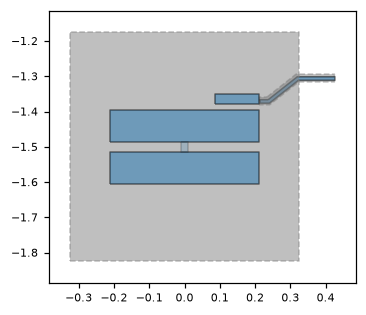

In [3]:
TransmonPocket(
    design,
    "Q1",
    options=dict(
        pos_x="0mm",
        pos_y="-1.5mm",
        pad_width="425um",
        pocket_height="650um",
        connection_pads=dict(readout=dict(loc_W=+1, loc_H=+1)),
    ),
)

## 2. Feedline + readout resonator

A coplanar feedline runs between two wirebond launchpads through a **coupled-line tee**, which couples to a meandered λ/4 resonator that runs down to the qubit. `total_length` sets the length of the meander (see the frequencies below).

option,value,parsed,description
chip,'main','main',Chip holding the QComponent.
layer,'1',1.0,Manufacturing layer used for the QComponent.
pin_inputs,,,
start_pin,,,Component and pin string pair. Define which pin to start from
component,'clt','clt',"Name of component to start from, which has a pin"
pin,'second_end','second_end',Name of pin used for pin_start
end_pin,,,Component and pin string pair. Define which pin to start from
component,'Q1','Q1',"Name of component to end on, which has a pin"
pin,'readout','readout',Name of pin used for pin_end
fillet,'90um',0.09,

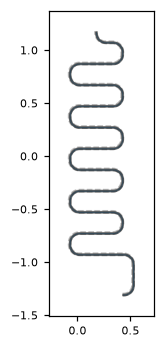

In [4]:
CoupledLineTee(
    design,
    "clt",
    options=dict(
        pos_x="0mm",
        pos_y="1.5mm",
        coupling_length="350um",
        down_length="300um",
        fillet="90um",
        open_termination=False,
    ),
)
LaunchpadWirebond(
    design, "LP1", options=dict(pos_x="-4mm", pos_y="1.5mm", orientation="0")
)
LaunchpadWirebond(
    design, "LP2", options=dict(pos_x="4mm", pos_y="1.5mm", orientation="180")
)

RoutePathfinder(
    design,
    "feed_L",
    options=dict(
        fillet="90um",
        pin_inputs=Dict(
            start_pin=Dict(component="LP1", pin="tie"),
            end_pin=Dict(component="clt", pin="prime_start"),
        ),
    ),
)
RoutePathfinder(
    design,
    "feed_R",
    options=dict(
        fillet="90um",
        pin_inputs=Dict(
            start_pin=Dict(component="clt", pin="prime_end"),
            end_pin=Dict(component="LP2", pin="tie"),
        ),
    ),
)

RouteMeander(
    design,
    "readout_res",
    options=dict(
        fillet="90um",
        total_length="7mm",
        lead=Dict(start_straight="100um", end_straight="100um"),
        pin_inputs=Dict(
            start_pin=Dict(component="clt", pin="second_end"),
            end_pin=Dict(component="Q1", pin="readout"),
        ),
    ),
)

### Resonator frequencies

With `open_termination=False` the resonator end at the tee is shorted to ground, so the tee couples to the resonator mainly inductively, at its current antinode (see the `CoupledLineTee` docstring). The λ/4 resonator is the tee's coupled arm (`second_cpw`), the meander and the qubit's readout pad stub (`readout_wire`) together: `total_length` covers the meander only, about 89 % of the line. The cell below prints the bare λ/4 frequency of each resonator and the meander length for a 7 GHz readout. With the lengths drawn here the readout resonators sit near 3.7-4.0 GHz, below the transmons (about 5.5 GHz for this pocket at L_J = 12.31 nH, tutorial 4.11); a readout above the qubits needs meanders of about 3.5 mm, and at these positions the shorter meander needs its fillet, spacing or the qubit position adjusted to keep `validate()` clean. Qubit and pad capacitances pull the actual frequencies further down.

In [5]:
import numpy as np
import pandas as pd
from qiskit_metal.analyses.em.cpw_calculations import guided_wavelength

C_LIGHT = 299792458.0


def drawn_length(component, name):
    """Length (mm) of one path of a component, filleted corners counted as arcs."""
    table = design.qgeometry.tables["path"]
    row = table[
        (table.component == design.components[component].id) & (table.name == name)
    ].iloc[0]
    fillet = 0.0 if pd.isna(row.fillet) else float(row.fillet)
    corners = max(len(row.geometry.coords) - 2, 0)
    return row.geometry.length - corners * (2 - np.pi / 2) * fillet


def sqrt_eps_eff(f_ghz):
    """10 um / 6 um CPW (the design defaults) on 750 um silicon, 200 nm film."""
    return guided_wavelength(f_ghz * 1e9, 10e-6, 6e-6, 750e-6, 200e-9)[1]


def resonator_summary(clt, q, res, f_target=7.0):
    """Bare lambda/4 frequency of the line tee arm + meander + qubit pad stub,
    and the meander length that would put it at f_target (GHz)."""
    extra = drawn_length(clt, "second_cpw") + drawn_length(q, "readout_wire")
    line = design.components[res].length + extra  # mm
    f_bare = C_LIGHT / (4 * line * 1e-3 * sqrt_eps_eff(6.0)) / 1e9
    meander_target = C_LIGHT / (4 * f_target * 1e9 * sqrt_eps_eff(f_target)) * 1e3 - extra
    print(
        f"{res}: meander {line - extra:.3f} mm + tee arm and pad stub {extra:.3f} mm"
        f" -> bare lambda/4 {f_bare:.2f} GHz; meander for {f_target} GHz: {meander_target:.2f} mm"
    )


for clt, q, res in [("clt", "Q1", "readout_res")]:
    resonator_summary(clt, q, res)

readout_res: meander 7.000 mm + tee arm and pad stub 0.846 mm -> bare lambda/4 3.88 GHz; meander for 7.0 GHz: 3.50 mm


## 3. Visualize

## Next steps

- **Inspect** the design tree: `design.components.keys()` and `design.qgeometry.tables`.
- **Export GDS** for fabrication: `design.renderers.gds.export_to_gds('chip.gds')` (Quantum Metal uses the modern `gdstk` backend).
- **Simulate**: render to Ansys HFSS/Q3D (the validation gold standard) or to the open-source FEM path (Gmsh + Elmer today; AWS Palace on the roadmap) to extract eigenmodes, *Q*, and the capacitance matrix.
- **Tweak**: every dimension above is a parameter — change `total_length` to retune a resonator (it is only the meander: the λ/4 line also includes the tee's coupled arm and the qubit's pad stub, about 0.85 mm here; `resonator_summary` gives the meander for a target frequency), or `pos_x`/`pos_y` to relayout.

In [6]:
design.components.keys()

['Q1', 'clt', 'LP1', 'LP2', 'feed_L', 'feed_R', 'readout_res']

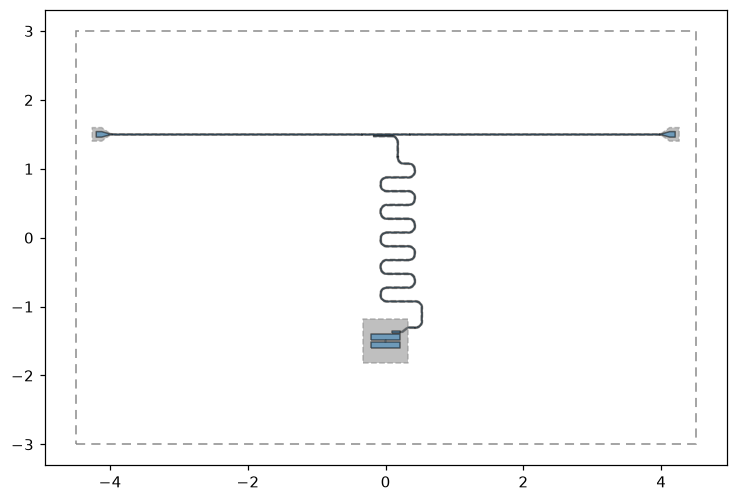

In [7]:
fig = qm.view(design)
qm.show_inline(fig)